In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity=1; np.random.seed(0)

In [ ]:
name='Chen2020_Head-and-Neck-2'; cat='Head-and-Neck'
pth      = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth,'data')
pth_in   = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig  = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb   = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load processed data
adata = sc.read_h5ad(os.path.join(pth_in,'processed.h5ad')); print(adata.shape)

(3674, 22080)


In [ ]:
# fit scFates principal tree on the integrated representation (params scaled to cell count)
scf.tl.tree(adata, method='ppt', Nodes=50, use_rep='X_pca_harmony', ndims_rep=19,
            ppt_lambda=300, ppt_sigma=0.5, ppt_nsteps=100, seed=0)
print('nodes:', adata.uns['graph']['B'].shape[0])

inferring a principal tree --> parameters used 
    50 principal points, sigma = 0.5, lambda = 300, metric = euclidean
    fitting:  23%|##3       | 23/100 [00:00<00:02, 30.30it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
nodes: 50


In [ ]:
# root at the least-differentiated state (Progenitor-like responsibility argmax); compute pseudotime
R = adata.obsm['X_R']; prog = (adata.obs['state']=='Progenitor-like').values
root = int(R[prog].sum(0).argmax()) if prog.sum()>=5 else int(R[(adata.obs['state']=='Cycling').values].sum(0).argmax())
scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_jobs=4, seed=0)
print('root node:', root, '| pseudotime %.1f -> %.1f'%(adata.obs.t.min(), adata.obs.t.max()),
      '| segments:', adata.uns['graph']['pp_seg'].shape[0])

node 35 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:02) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
root node: 35 | pseudotime 0.1 -> 10.9 | segments: 10


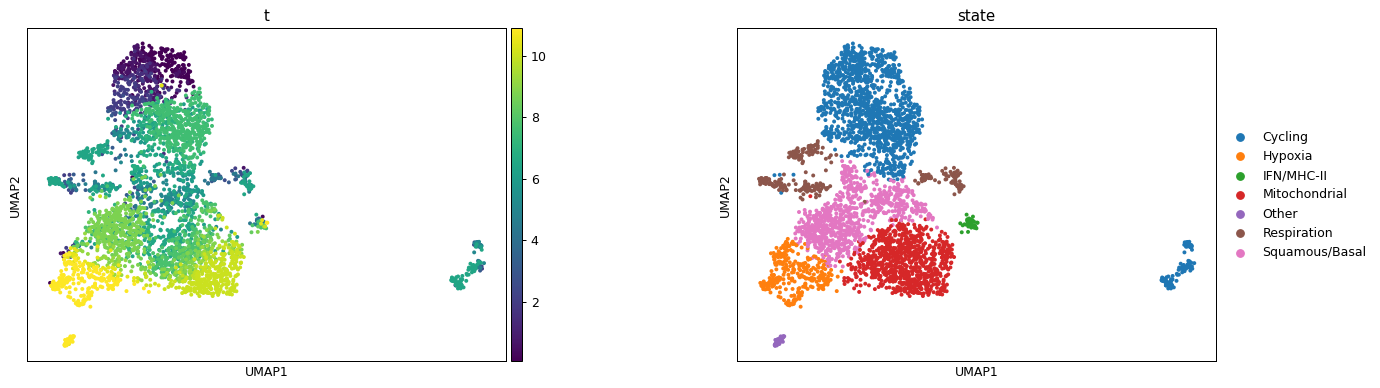

In [ ]:
# visual inspection -- pseudotime + states
sc.pl.umap(adata, color=['t','state'], size=40, wspace=.35)

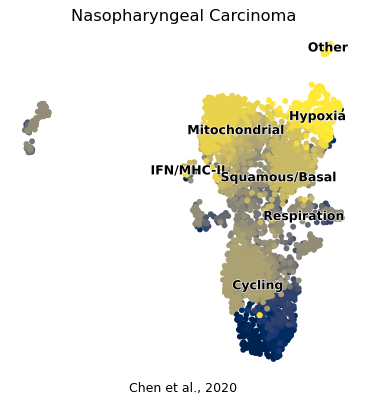

In [ ]:
# save manifold data + figure (manifold.pdf) -- pseudotime cividis with state overlay
adata.write(os.path.join(pth_in,'manifold.h5ad'))
fig, ax = plt.subplots(1,1, figsize=(5,5))
sc.pl.umap(adata, color='t', cmap='cividis', size=90, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=90, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Nasopharyngeal Carcinoma', size=13)
ax.text(.5,-.05,'Chen et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()